# Synthetic quantile data: reusable generator

Import the class, choose a model, and call `generate()`. Every call returns a **complete pandas DataFrame**; `head()` only limits the preview. Set `plot=True` for a figure like the reference, or call `model.plot(data)` later without resampling.

The original notebook is in [`synthetic_data/Quantile_Breakpoint_Simulation.ipynb`](synthetic_data/Quantile_Breakpoint_Simulation.ipynb), beside the shared implementation [`generator.py`](synthetic_data/generator.py).

$$m(x)=\beta_0+\beta_1x+\sum_{j=1}^K\delta_j(x-\kappa_j)_+,$$
$$Y=\operatorname{expit}\{\operatorname{logit}(m(X))+\sigma(X)[U-F_U^{-1}(\tau)]\}.$$

The shift makes $m(x)$ exactly the conditional $\tau$-quantile. Scale is linear between the two `sigma` endpoints **on the logit scale**. `noise="t"` with `df=8` is the original default; normal noise is also available. The dark curve and dashed null line are known model curves, not estimated regressions. Other conditional quantiles generally need not be piecewise linear.

In [1]:
%matplotlib inline
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from synthetic_data import QuantileDataGenerator

pd.set_option("display.precision", 4)

## 1. Sparse data near two breakpoints

`near_share=0.05` sets the probability of falling in the **union** of the windows to 5%; `half_width=0.05` sets each window's half-width. The realized count is random, not exactly 5% of the sample. Within and outside the windows, the base Beta shape is preserved.

In [ ]:
sparse_model = QuantileDataGenerator(
    n=150, tau=0.8,
    breakpoints=(0.4, 0.7), slope_changes=(-0.9, 0.9),
    beta0=0.65, beta1=-0.2,
    sigma=(0.8, 0.2), noise="t", df=8,
    near_share=0.05, half_width=0.05, seed=2026,
)
sparse_data = sparse_model.generate(plot=True)  # Always returns a DataFrame.
print(f"Stored all {len(sparse_data)} observations; {sparse_data.near_breakpoint.sum()} inside windows.")
display(sparse_data.head())

: 

`X` and `Y` are the scatter coordinates. The extra columns store the true target quantile, reference null line, logit noise scale, shifted residual, and window membership. `data.attrs` records the configuration. To get only the observations, use `data[["X", "Y"]]`.

## 2. Zero, one, or K breakpoints

There is one slope change per breakpoint. Changes accumulate: after knot $j$ the slope is `beta1 + sum(slope_changes[:j+1])`. For no knots, pass **both** empty tuples. The generator checks that the entire true curve stays inside $(0,1)$ before generating anything.

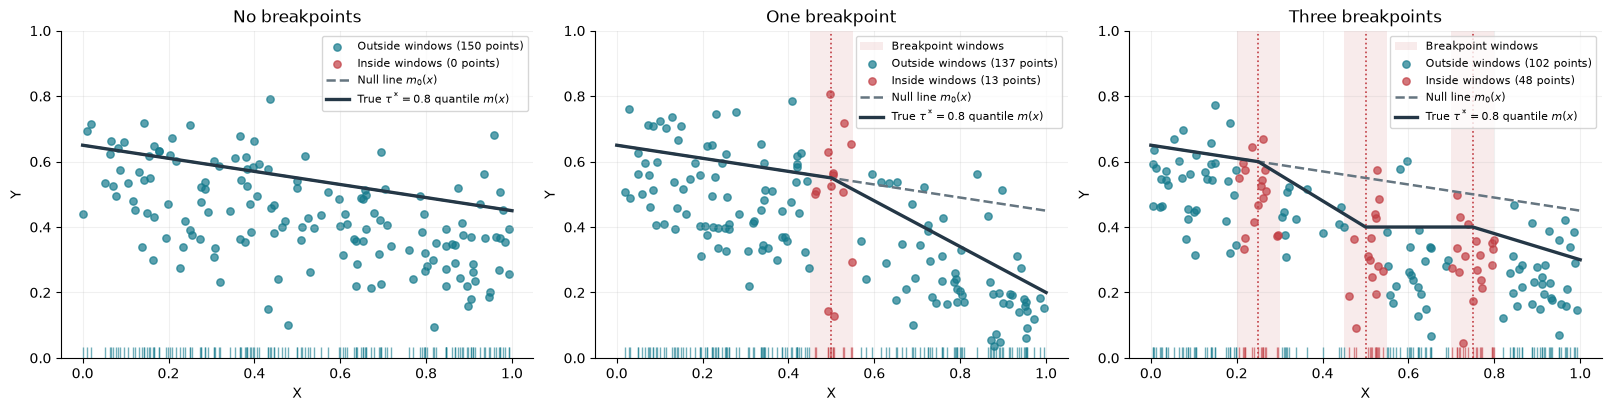

No breakpoints (150, 7)


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.8473,0.2732,0.4805,0.4805,0.5695,-1.5810,False
1,0.7905,0.3854,0.4919,0.4919,0.5581,-0.7785,False
2,0.1628,0.2999,0.6174,0.6174,0.4326,-3.0667,False


One breakpoint (150, 7)


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.2048,0.4032,0.6090,0.6090,0.4410,-1.8947,False
1,0.9545,0.1430,0.2319,0.4591,0.5909,-1.0030,False
2,0.3518,0.3349,0.5796,0.5796,0.4704,-2.1414,False


Three breakpoints (150, 7)


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.5136,0.3653,0.4000,0.5473,0.5027,-0.2920,True
1,0.6028,0.3389,0.4000,0.5294,0.5206,-0.5044,False
2,0.8535,0.1598,0.3586,0.4793,0.5707,-1.8898,False


In [3]:
models = {
    "No breakpoints": QuantileDataGenerator(breakpoints=(), slope_changes=(), seed=10),
    "One breakpoint": QuantileDataGenerator(breakpoints=(0.5,), slope_changes=(-0.5,), seed=11),
    "Three breakpoints": QuantileDataGenerator(
        breakpoints=(0.25, 0.5, 0.75), slope_changes=(-0.6, 0.8, -0.4), seed=12),
}
datasets = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, (name, model) in zip(axes, models.items()):
    datasets[name] = model.generate()
    model.plot(datasets[name], ax=ax, title=name)
plt.show()
for name, data in datasets.items():
    print(name, data.shape)
    display(data.head(3))

## 3. Change the sample size, knot locations, and slope-change strength

`replace` creates a new configuration without mutating the old one. `generate(n=...)` can also override just the sample size. Both datasets below contain every simulated observation.

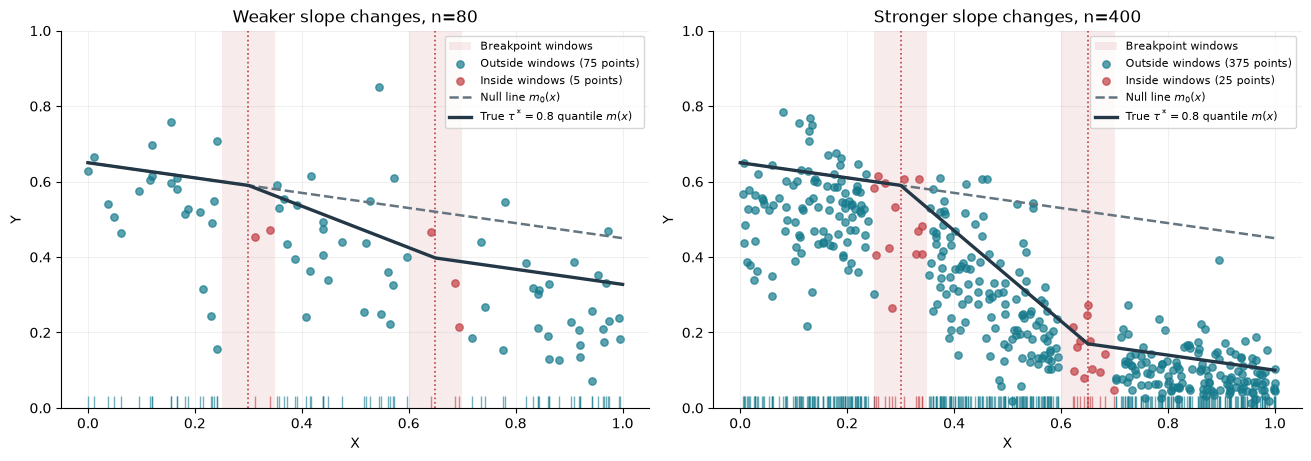

,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.2364,0.5485,0.6027,0.6027,0.4473,-0.4969,False
1,0.3725,0.4334,0.5501,0.5755,0.4745,-0.9883,False
2,0.1871,0.5282,0.6126,0.6126,0.4374,-0.7896,False
3,0.4489,0.3397,0.5081,0.5602,0.4898,-1.4229,False
4,0.8627,0.1302,0.3550,0.4775,0.5725,-2.2740,False


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.7892,0.0385,0.1422,0.4922,0.5578,-2.5467,False
1,0.9814,0.0316,0.1037,0.4537,0.5963,-2.1253,False
2,0.7816,0.0626,0.1437,0.4937,0.5563,-1.6557,False
3,0.9764,0.0861,0.1047,0.4547,0.5953,-0.3636,False
4,0.4440,0.3072,0.4172,0.5612,0.4888,-0.9804,False


In [4]:
weak_model = replace(sparse_model, n=80, breakpoints=(0.3, 0.65),
                     slope_changes=(-0.35, 0.35), seed=31)
strong_model = replace(weak_model, n=400, slope_changes=(-1.0, 1.0), seed=32)
weak_data = weak_model.generate()
strong_data = strong_model.generate()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
weak_model.plot(weak_data, ax=axes[0], title="Weaker slope changes, n=80")
strong_model.plot(strong_data, ax=axes[1], title="Stronger slope changes, n=400")
plt.show()
display(weak_data.head(), strong_data.head())

## 4. Control the window widths and sampling probabilities

`near_share=None` keeps the original Beta design. A number sets the probability in the window union; 0 excludes those regions, and 1 samples only inside them. Use a tuple of half-widths for different widths at different breakpoints. Overlapping windows are merged and windows crossing the support boundary are clipped. Assigning positive probability to an empty region raises an error.

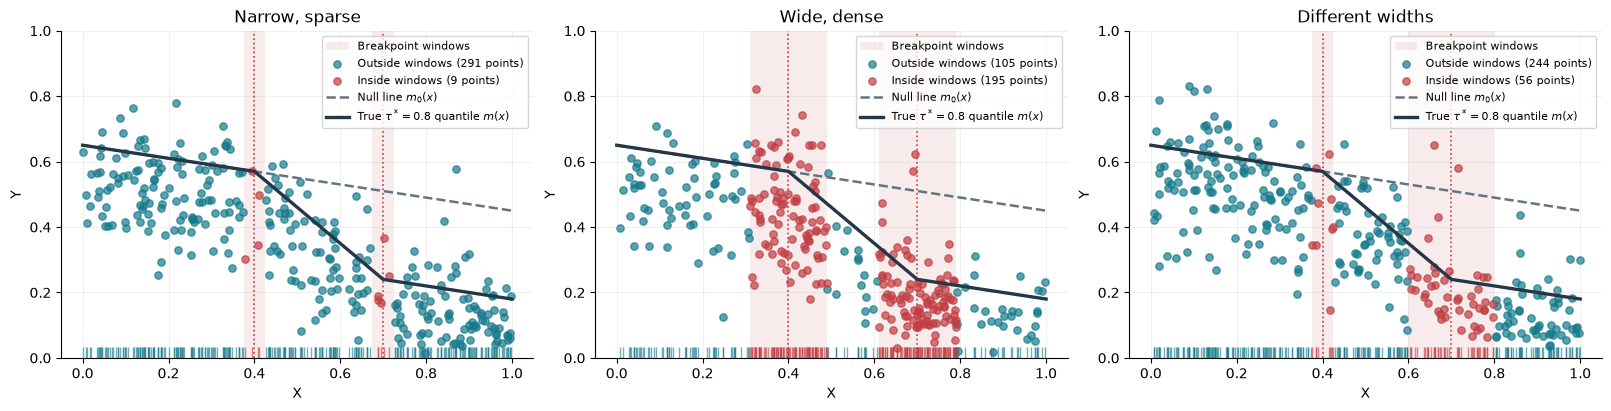

,scenario,n,half_width,target_probability,realized_share
0,"Narrow, sparse",300,0.025,0.05,0.0300
1,"Wide, dense",300,0.09,0.65,0.6500
2,Different widths,300,"(0.025, 0.1)",0.20,0.1867


Narrow, sparse


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.9065,0.1092,0.1987,0.4687,0.5813,-1.2127,False
1,0.3273,0.7089,0.5845,0.5845,0.4655,1.1789,False
2,0.9943,0.0750,0.1811,0.4511,0.5989,-1.6766,False


Wide, dense


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.1074,0.4727,0.6285,0.6285,0.4215,-1.5073,False
1,0.7088,0.1070,0.2382,0.5082,0.5418,-1.7698,True
2,0.7940,0.0215,0.2212,0.4912,0.5588,-4.5823,False


Different widths


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.5556,0.1545,0.3989,0.5389,0.5111,-2.5233,False
1,0.3839,0.5819,0.5732,0.5732,0.4768,0.0746,True
2,0.7456,0.1884,0.2309,0.5009,0.5491,-0.4687,True


In [5]:
window_models = {
    "Narrow, sparse": replace(sparse_model, n=300, half_width=0.025, near_share=0.05, seed=41),
    "Wide, dense": replace(sparse_model, n=300, half_width=0.09, near_share=0.65, seed=42),
    "Different widths": replace(sparse_model, n=300, half_width=(0.025, 0.10), near_share=0.20, seed=43),
}
window_datasets = {}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, (name, model) in zip(axes, window_models.items()):
    data = window_datasets[name] = model.generate()
    model.plot(data, ax=ax, title=name)
    rows.append(dict(scenario=name, n=len(data), half_width=model.half_width,
                     target_probability=model.near_share, realized_share=data.near_breakpoint.mean()))
plt.show()
display(pd.DataFrame(rows))
for name, data in window_datasets.items():
    print(name)
    display(data.head(3))

## 5. Change the scale, residual shape, target quantile, and base predictor design

Equal `sigma` endpoints give constant noise scale on the logit scale; unequal endpoints control heteroskedasticity. Lower Student-t `df` gives heavier residual tails. `x_beta=(1,1)` is uniform; other positive Beta shapes alter the predictor density. `x_range` can change the support, with knots specified on that same scale.

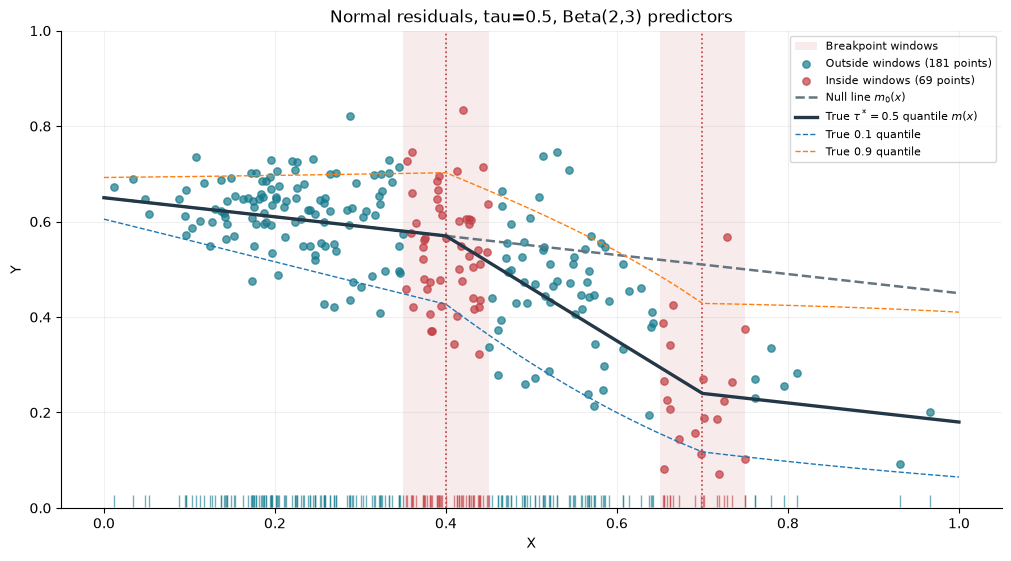

,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.3777,0.4581,0.5745,0.5745,0.4333,-1.0805,True
1,0.5727,0.2130,0.3801,0.5355,0.5795,-1.4106,False
2,0.6624,0.2074,0.2814,0.5175,0.6468,-0.6235,True
3,0.3235,0.6987,0.5853,0.5853,0.3927,1.2646,False
4,0.4395,0.4350,0.5265,0.5621,0.4797,-0.7664,True


In [6]:
normal_model = QuantileDataGenerator(
    n=250, tau=0.5, noise="normal", sigma=(0.15, 0.9),
    x_beta=(2, 3), near_share=None, seed=50,
)
normal_data = normal_model.generate()
normal_model.plot(normal_data, quantiles=(0.1, 0.9),
                  title="Normal residuals, tau=0.5, Beta(2,3) predictors")
plt.show()
display(normal_data.head())

## 6. Supply your own X, or evaluate the exact conditional quantile

Passing `x=` bypasses the random predictor design and generates one response per supplied value. Do not pass `n` at the same time. `location(x)`, `scale(x)`, and `true_quantile(x, tau)` also accept scalar predictors.

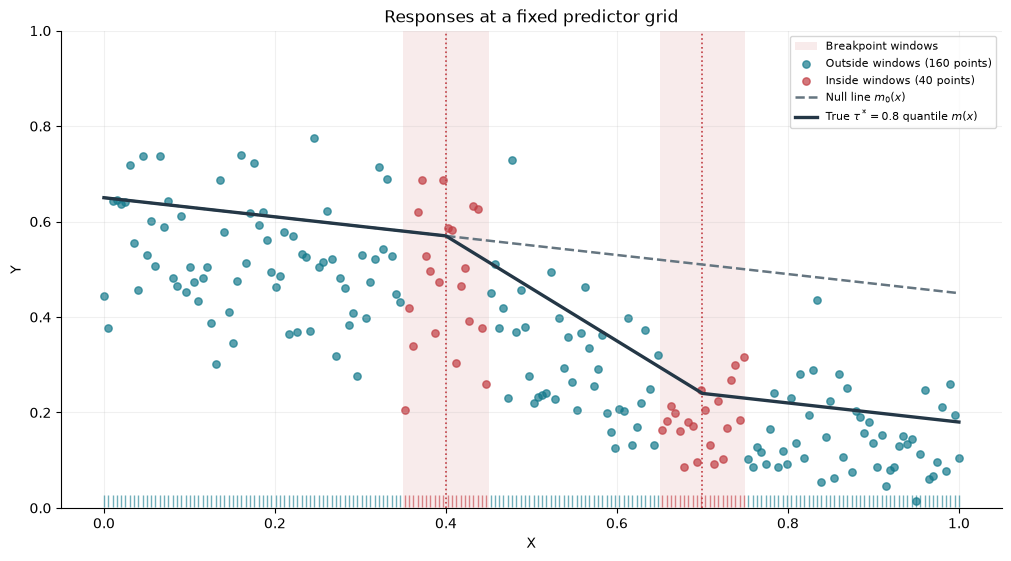

,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.0000,0.4450,0.650,0.650,0.400,-2.0995,False
1,0.0050,0.3762,0.649,0.649,0.401,-2.7937,False
2,0.0101,0.6424,0.648,0.648,0.402,-0.0606,False
3,0.0151,0.6449,0.647,0.647,0.403,-0.0229,False
4,0.0201,0.6363,0.646,0.646,0.404,-0.1042,False


,X,Q_0.1,Q_0.8,Q_0.9
0,0.0000,0.4267,0.650,0.6947
1,0.0050,0.4251,0.649,0.6939
2,0.0101,0.4234,0.648,0.6930
3,0.0151,0.4218,0.647,0.6922
4,0.0201,0.4202,0.646,0.6914


In [7]:
fixed_x = np.linspace(0, 1, 200)
fixed_data = sparse_model.generate(x=fixed_x, seed=60)
sparse_model.plot(fixed_data, title="Responses at a fixed predictor grid")
plt.show()
quantile_table = pd.DataFrame({
    "X": fixed_x,
    "Q_0.1": sparse_model.true_quantile(fixed_x, 0.1),
    "Q_0.8": sparse_model.true_quantile(fixed_x, 0.8),
    "Q_0.9": sparse_model.true_quantile(fixed_x, 0.9),
})
np.testing.assert_allclose(quantile_table["Q_0.8"], sparse_model.location(fixed_x))
display(fixed_data.head(), quantile_table.head())

## 7. Data only, reproducibility, and export

With the same explicit seed, you get the same dataset. Without an override, each `generate()` call advances the object's random stream. `plot(data)` does not sample again. The full DataFrames above remain available for regression or export. Here is a reproducible data-only call:

In [8]:
data_only = sparse_model.generate(n=500, seed=123)  # No figure by default.
repeated = sparse_model.generate(n=500, seed=123)
pd.testing.assert_frame_equal(data_only, repeated)
print(data_only.shape)
display(data_only.head())

# Optional exports (uncomment to write files):
# data_only.to_csv("synthetic_dataset.csv", index=False)
# ax = sparse_model.plot(data_only)
# ax.figure.savefig("synthetic_dataset.png", dpi=300, bbox_inches="tight")

(500, 7)


,X,Y,m_true,m_null,sigma,Z,near_breakpoint
0,0.9495,0.1198,0.1901,0.4601,0.5899,-0.9245,False
1,0.8077,0.1364,0.2185,0.4885,0.5615,-1.0158,False
2,0.8479,0.1017,0.2104,0.4804,0.5696,-1.5037,False
3,0.2494,0.6264,0.6001,0.6001,0.4499,0.2460,False
4,0.9811,0.1186,0.1838,0.4538,0.5962,-0.8640,False


To use the module in another Python environment, install this repository with `python -m pip install "/path/to/STAT-664-repo[plot]"`, or copy the `synthetic_data` folder into your project. Then use the same `from synthetic_data import QuantileDataGenerator` import. The Monte Carlo notebook is not imported or executed by the package.